# C04-DB — DBSCAN trên RFM + AOV + Diversity + QtyPerOrder + Tenure (log1p + Standard + PCA 90%)

Thí nghiệm **C04-DB** (người chạy: Nguyên) theo chiến lược model. So với C01, **thêm 2 feature: QtyPerOrder** (số lượng hàng trung bình mỗi đơn) **và Tenure** (số ngày từ lần mua đầu đến lần mua cuối). Pipeline: làm sạch → 7 feature → `log1p` mọi biến → StandardScaler → PCA giữ ≥ 90% phương sai → DBSCAN.

Theo bảng chiến lược, C04 được đối chiếu với **C02** (chỉ thêm QtyPerOrder) và **C03** (chỉ thêm Tenure) để biết hai biến có tương tác hay không. C01-DB, C02-DB và C03-DB chưa có trong repo nên cả ba được dựng lại ngay trong notebook, cùng lưới `eps × min_samples` và quy tắc chọn của A01-DB (An) để so cùng điều kiện.

## Params

In [1]:
FEATURES_C01 = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
SETS = {"C01": FEATURES_C01,
        "C02": FEATURES_C01 + ["QtyPerOrder"],
        "C03": FEATURES_C01 + ["Tenure"],
        "C04": FEATURES_C01 + ["QtyPerOrder", "Tenure"]}      # C04: thêm cả hai
FEATURES = SETS["C04"]
PCA_VAR = 0.90                      # giữ ít nhất 90% phương sai (giống C01)
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]                       # giống A01-DB
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]       # giống A01-DB (cùng đơn vị Standard, không cần quy đổi)
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..C02), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes, QtyPerOrder = avg_quantity_per_order,
# Tenure = observed_span_days (ngày mua cuối − ngày mua đầu, đúng định nghĩa của bảng chiến lược)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(
    columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity", "avg_quantity_per_order": "QtyPerOrder",
             "observed_span_days": "Tenure"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
assert np.allclose(df["QtyPerOrder"], df["total_quantity"] / df["Frequency"], atol=0.01)   # QtyPerOrder = tổng số lượng / Frequency
print("Dữ liệu đầu vào:", X.shape)
zero = X["Tenure"] == 0
print(f"Khách có Tenure = 0 ngày: {int(zero.sum())} ({zero.mean():.1%}), trong đó Frequency = 1: {int((zero & (X['Frequency'] == 1)).sum())}"
      f" | tổng khách Frequency = 1: {int((X['Frequency'] == 1).sum())}")
X.describe().round(2)

Dữ liệu đầu vào: (4327, 7)
Khách có Tenure = 0 ngày: 1506 (34.8%), trong đó Frequency = 1: 1502 | tổng khách Frequency = 1: 1504


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.0,4327.00
mean,93.04,4.25,1944.95,372.40,61.49,227.4,130.59
std,99.98,7.64,8441.89,466.49,85.31,298.5,132.24
min,1.00,1.00,2.90,2.90,1.00,1.0,0.00
25%,18.00,1.00,301.52,175.47,16.00,93.0,0.00
50%,51.00,2.00,657.90,286.70,35.00,161.0,92.14
75%,143.00,5.00,1624.10,421.99,77.00,272.0,252.03
max,374.00,206.00,278748.02,14844.77,1784.00,7824.0,373.10


**Nhận xét:** 4.327 khách, 7 feature, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). **Tenure lấy từ cột `observed_span_days`** (ngày mua cuối − ngày mua đầu, đúng định nghĩa trong bảng chiến lược; tôi đã đối chiếu với ngày mua trong raw ngoài notebook này, khớp 99,2% khách). Cột `observed_tenure_days` có nghĩa khác (ngày tham chiếu − ngày mua đầu) nên không dùng.

Điểm cần lưu ý: **1.506 khách (34,8%) có Tenure = 0**, và gần như trùng nhóm mua đúng một lần (1.502 trong số 1.504 khách Frequency = 1). Nghĩa là Tenure phần lớn là cờ "mua một lần" cộng với độ dài quan hệ của số còn lại. Đây là file làm sạch cũ của nhóm, không phải feature tính thẳng từ raw (chi tiết ở A02-KM).

## `log1p`, StandardScaler và PCA giữ 90% phương sai (4 bộ feature)

Dựng không gian cho cả C01, C02, C03 (để đối chiếu) và C04.

In [3]:
def build_space(cols):
    Xs = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X[cols])
    ev = PCA(svd_solver="full").fit(Xs).explained_variance_ratio_
    cum = np.cumsum(ev)
    n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
    pca = PCA(n_components=n_pc, svd_solver="full").fit(Xs)
    return {"cols": cols, "pca": pca, "Z": pca.transform(Xs), "ev": ev, "cum": cum, "n_pc": n_pc}

spaces = {name: build_space(cols) for name, cols in SETS.items()}
Z = spaces["C04"]["Z"]

pd.DataFrame([{"Bộ feature": n, "Số biến": len(s["cols"]), "Số PC giữ lại": s["n_pc"],
               "Phương sai giữ lại": round(s["cum"][s["n_pc"] - 1], 4), "PC cuối (phương sai)": round(s["ev"][-1], 4)}
              for n, s in spaces.items()])

,Bộ feature,Số biến,Số PC giữ lại,Phương sai giữ lại,PC cuối (phương sai)
0,C01,5,3,0.9240,0.0006
1,C02,6,3,0.9089,0.0005
2,C03,6,4,0.9592,0.0001
3,C04,7,4,0.9396,0.0001


In [4]:
c4 = spaces["C04"]
print("C04 — phương sai từng PC:", c4["ev"].round(4))
print("C04 — phương sai tích lũy:", c4["cum"].round(4))
pd.DataFrame(c4["pca"].components_, index=[f"PC{i+1}" for i in range(c4["n_pc"])], columns=FEATURES).round(3)

C04 — phương sai từng PC: [5.682e-01 2.332e-01 8.170e-02 5.650e-02 3.720e-02 2.300e-02 1.000e-04]
C04 — phương sai tích lũy: [0.5682 0.8014 0.8831 0.9396 0.9769 0.9999 1.    ]


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure
PC1,-0.313,0.409,0.483,0.317,0.410,0.305,0.374
PC2,0.306,-0.356,0.070,0.569,-0.021,0.563,-0.365
PC3,0.893,0.205,0.150,-0.023,0.131,-0.139,0.318
PC4,0.030,-0.183,-0.244,-0.183,0.898,-0.046,-0.253


**Nhận xét:** Thêm QtyPerOrder không đổi số PC cần giữ (C02: 3 PC, 90,89%) nhưng **thêm Tenure làm cần 4 PC** (C03: 4 PC, 95,92%; C04: 4 PC, 93,96%), vì Tenure là hướng gần như độc lập với các biến còn lại. Ở C04, 4 PC giữ 93,96%; PC cuối chỉ giữ 0,01% phương sai, đúng hướng AOV phụ thuộc tuyến tính vào Frequency và Monetary đã gặp ở C01. Số chiều lớn hơn (4 so với 3) làm khoảng cách giữa các khách lớn hơn một chút.

## Chọn eps bằng đồ thị k-distance (C04)

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó), sắp xếp tăng dần. Điểm bẻ cong mạnh gợi ý eps.

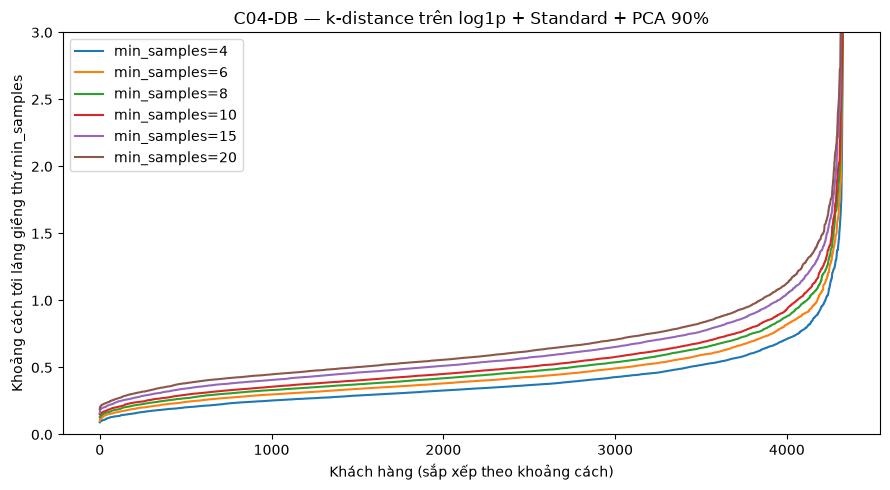

,4,6,8,10,15,20
P50,0.341,0.396,0.436,0.469,0.532,0.577
P90,0.653,0.742,0.803,0.855,0.960,1.038
P95,0.796,0.909,0.995,1.058,1.184,1.286
P99,1.289,1.464,1.660,1.725,1.915,2.109


In [5]:
kd = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]) for ms in MIN_SAMPLES_GRID}

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kd.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("C04-DB — k-distance trên log1p + Standard + PCA 90%")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

pd.DataFrame({ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99]) for ms, d in kd.items()},
             index=["P50", "P90", "P95", "P99"]).round(3)

**Nhận xét:** Khoảng cách tới láng giềng không còn nhỏ như ở các không gian ít chiều hơn: P50 từ 0,34 (min_samples = 4) đến 0,58 (min_samples = 20), P99 từ 1,29 đến 2,11. Đồ thị không có khuỷu rõ: khách trải thành một khối liên tục rồi tăng dần ở đuôi. Cùng đơn vị Standard như A01-DB nên **dùng nguyên lưới eps gốc (0,1–2,0)**, và dải này vẫn phủ cả vùng P50 lẫn P99.

## Quét lưới eps × min_samples (C04)

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [6]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Zs), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Zs[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Zs[mask], labels[mask]), 4)
    return row, labels

def run_grid(Zs):
    pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID]
    out = [run_dbscan(Zs, e, m) for e, m in pairs]
    return pd.DataFrame([r for r, _ in out]), {p: l for p, (_, l) in zip(pairs, out)}

def select(g):
    # ≥ 2 cụm, nhiễu ≤ 5%, Silhouette cao nhất; hòa thì lấy cấu hình đứng trước trong lưới
    valid = g[(g["n_clusters"] >= MIN_CLUSTERS) & (g["noise_pct"] <= MAX_NOISE * 100)]
    return valid.sort_values("silhouette", ascending=False, kind="stable").iloc[0], len(valid)

grid, lab_c04 = run_grid(Z)
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
print("Số cấu hình chỉ 1 cụm:", int((grid["n_clusters"] == 1).sum()))
print("Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách:",
      int(((grid["n_clusters"] >= 2) & (grid["largest_pct"] < 90)).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(8)

Số cấu hình đã chạy: 54
Số cấu hình có >= 2 cụm: 26
Số cấu hình chỉ 1 cụm: 23
Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách: 24


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
0,4,0.1,4,99.58,0.14,4,0.7459,0.3091
37,15,0.2,4,97.43,1.41,15,0.6238,0.5752
28,10,0.2,6,95.42,1.83,10,0.4689,0.5682
49,20,0.5,2,44.58,29.26,1132,0.4449,0.9164
40,15,0.5,2,36.05,36.12,1204,0.4296,0.9405
31,10,0.5,3,26.30,44.12,8,0.3628,0.7992
6,4,1.0,3,1.46,98.31,4,0.2641,0.6479
48,20,0.4,6,72.24,18.95,21,0.2618,0.8522


**Nhận xét:** 26/54 cấu hình có ≥ 2 cụm. Các cấu hình có Silhouette cao nhất (0,43–0,75) đều là cấu hình **gán 36–99,6% khách vào nhiễu** (ví dụ min_samples = 4, eps = 0,1: 4 cụm nhưng 99,58% khách là nhiễu), nên không thể coi là phân cụm. Cả 24 cấu hình chia khối chính đều hơn (cụm lớn nhất < 90%) cũng bị loại vì nhiễu > 5% (xem bước chọn cấu hình bên dưới: chỉ 2 cấu hình đạt điều kiện nhiễu, và cả hai đều có cụm lớn nhất ≥ 90%).

## Chọn cấu hình

Cùng quy tắc A01-DB (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, **Silhouette cao nhất**.

In [7]:
best, n_valid = select(grid)
print(f"Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): {n_valid}")
print("Cấu hình được chọn:")
print(best.to_string())
print()
grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]

Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): 2
Cấu hình được chọn:
min_samples     4.0000
eps             1.0000
n_clusters      3.0000
noise_pct       1.4600
largest_pct    98.3100
smallest        4.0000
silhouette      0.2641
dbi             0.6479



,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
5,4,0.7,6,4.83,94.66,3,-0.1069,0.7912
6,4,1.0,3,1.46,98.31,4,0.2641,0.6479


**Nhận xét:** Chỉ **2 cấu hình** đạt điều kiện. Cấu hình được chọn là `min_samples = 4`, `eps = 1,0`: 3 cụm, nhiễu 1,46% (63 khách), cụm lớn nhất 98,31%, cụm nhỏ nhất 4 khách; Silhouette 0,2641, DBI 0,6479. Cấu hình còn lại (`min_samples = 4`, `eps = 0,7`: 6 cụm, nhiễu 4,83%) có Silhouette âm (−0,1069). Vì chỉ có một cấu hình dương nên lựa chọn này gần như là duy nhất chứ không phải kết quả của một cuộc cạnh tranh giữa nhiều cấu hình.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary của nhóm.

In [8]:
labels = lab_c04[(float(best["eps"]), int(best["min_samples"]))]
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
        QtyPerOrder=("QtyPerOrder", "median"), Tenure=("Tenure", "median"), Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,,
-1,63,11.0,6.0,9341.3,1171.1,37.0,672.0,299.0,1.5,26.4
0,4254,52.0,2.0,653.2,284.5,35.0,160.0,90.9,98.3,72.8
1,4,87.0,1.0,4449.3,4449.3,194.0,2754.5,0.0,0.1,0.2
2,6,69.0,6.0,6863.3,1299.9,15.0,1052.4,246.9,0.1,0.6


**Nhận xét:**
- **Cụm 0 (4.254 khách, 98,3%)** có hồ sơ gần trung vị toàn bộ khách (Recency 52, Frequency 2, Monetary ≈ 653, QtyPerOrder 160) và đóng góp 72,8% Monetary.
- **Cụm 1 (4 khách)**: Frequency 1, Monetary = AOV ≈ 4.449 (một đơn duy nhất rất lớn), QtyPerOrder ≈ 2.755, Diversity 194, Tenure 0 → **khách mua một đơn khổng lồ**.
- **Cụm 2 (6 khách)**: Frequency 6, Monetary ≈ 6.863, QtyPerOrder ≈ 1.052 nhưng Diversity chỉ 15 → **khách mua sỉ ít chủng loại**.
- **63 khách nhiễu (1,5%)**: Recency 11, Frequency 6, Monetary ≈ 9.341, AOV ≈ 1.171, QtyPerOrder ≈ 672 — nhóm giá trị cao nhưng không đủ gần nhau để thành cụm; chiếm 26,4% Monetary.

Tức là DBSCAN chỉ tách phần đuôi ngoại lai theo cỡ đơn hàng (hai biến mới QtyPerOrder và AOV đóng vai trò chính), chưa chia khối chính thành phân khúc.

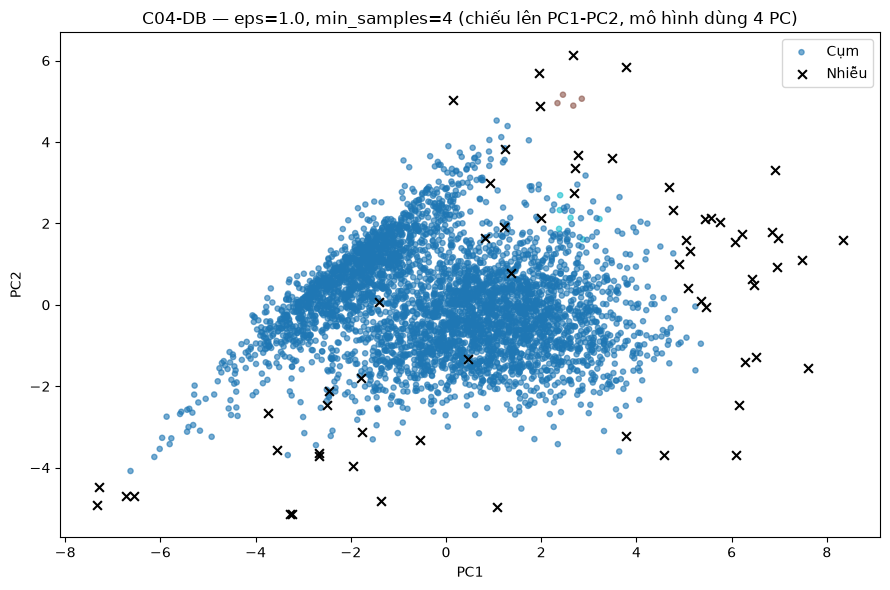

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=40, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"C04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (chiếu lên PC1-PC2, mô hình dùng {c4['n_pc']} PC)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Phần lớn khách dồn thành một khối liền; các điểm nhiễu và cụm nhỏ rải ở phần đuôi xa của PC1-PC2. Hình xác nhận DBSCAN chỉ bắt phần đuôi ngoại lai.

## Đối chiếu C01, C02, C03 (dựng lại cùng điều kiện)

Chạy đúng lưới 54 cấu hình và quy tắc chọn trên 3 bộ feature còn lại, rồi so cấu hình được chọn của mỗi bộ. ARI đo mức trùng nhóm giữa hai cách chia (nhãn nhiễu −1 được tính như một nhóm), 1,0 là giống hệt.

In [10]:
runs = {}
for name, sp in spaces.items():
    g, lab = run_grid(sp["Z"])
    b, n_ok = select(g)
    runs[name] = {"grid": g, "labels": lab[(float(b["eps"]), int(b["min_samples"]))], "best": b, "n_valid": n_ok}
assert (runs["C04"]["labels"] == labels).all()

cmp = pd.DataFrame([{
    "Bộ feature": n, "Số biến": len(spaces[n]["cols"]), "Số PC": spaces[n]["n_pc"],
    "Cấu hình có >= 2 cụm": int((r["grid"]["n_clusters"] >= 2).sum()), "Cấu hình đạt điều kiện": r["n_valid"],
    "eps": float(r["best"]["eps"]), "min_samples": int(r["best"]["min_samples"]), "Số cụm": int(r["best"]["n_clusters"]),
    "Nhiễu (khách)": int((r["labels"] == -1).sum()), "Nhiễu (%)": float(r["best"]["noise_pct"]),
    "Cụm lớn nhất (%)": float(r["best"]["largest_pct"]), "Silhouette": float(r["best"]["silhouette"]),
    "DBI": float(r["best"]["dbi"])} for n, r in runs.items()])

names = list(runs)
ari = pd.DataFrame([[round(adjusted_rand_score(runs[a]["labels"], runs[b]["labels"]), 3) for b in names] for a in names],
                   index=names, columns=names)
print("ARI giữa các cấu hình được chọn:"); print(ari.to_string())
cmp

ARI giữa các cấu hình được chọn:
       C01    C02    C03    C04
C01  1.000  0.780  0.446  0.767
C02  0.780  1.000  0.488  0.755
C03  0.446  0.488  1.000  0.549
C04  0.767  0.755  0.549  1.000


,Bộ feature,Số biến,Số PC,Cấu hình có >= 2 cụm,Cấu hình đạt điều kiện,eps,min_samples,Số cụm,Nhiễu (khách),Nhiễu (%),Cụm lớn nhất (%),Silhouette,DBI
0,C01,5,3,24,4,0.7,4,2,49,1.13,98.71,0.3889,0.5743
1,C02,6,3,25,3,0.7,4,4,60,1.39,98.36,0.3848,0.4502
2,C03,6,4,27,2,0.7,4,3,165,3.81,95.89,-0.0083,0.8994
3,C04,7,4,26,2,1.0,4,3,63,1.46,98.31,0.2641,0.6479


**Nhận xét:**
- **Cả bốn bộ đều chỉ tách ngoại lai:** mỗi bộ chọn 2–4 cụm với cụm lớn nhất 95,9–98,7% khách; nhiễu 1,1–3,8%.
- **Tenure là biến làm đổi nhiều nhất:** C03 (thêm Tenure) có ARI chỉ 0,446 so với C01 và 0,488 so với C02, và cấu hình được chọn có **Silhouette âm (−0,0083)**, nhiễu 3,81% — chỉ 2 cấu hình đạt điều kiện nhiễu, và cả hai đều xấu. Ngược lại QtyPerOrder gần như chỉ dịch ranh giới: C02 so với C01 có ARI 0,780.
- **Tương tác giữa QtyPerOrder và Tenure:** C04 (cả hai) lại gần C01 và C02 hơn gần C03: ARI 0,767 với C01, 0,755 với C02, 0,549 với C03. Nghĩa là khi thêm QtyPerOrder, ảnh hưởng của Tenure bị giảm đi (cấu hình chọn của C04 có Silhouette dương 0,2641 và cụm nhỏ nhất 4 khách, kiểu tách ngoại lai như C01–C02), nhưng không có tương tác kiểu "cộng dồn".
- **Chọn cấu hình rất mong manh ở C03 và C04:** chỉ 2 cấu hình đạt điều kiện ở mỗi bộ (C01: 4; C02: 3). Silhouette không so trực tiếp được giữa các không gian khác nhau (3 hay 4 PC).

## Lưu kết quả

In [11]:
grid.to_csv(OUT / "dbscan_c04_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_c04_labels.csv", index=False)
params = {"experiment": "C04-DB", "features": FEATURES,
          "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes", "QtyPerOrder": "avg_quantity_per_order",
                              "Tenure": "observed_span_days"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": c4["n_pc"], "pca_variance_kept": float(c4["cum"][c4["n_pc"] - 1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "configs_passing_rule": int(n_valid),
          "ari_vs_c01": float(ari.loc["C04", "C01"]), "ari_vs_c02": float(ari.loc["C04", "C02"]), "ari_vs_c03": float(ari.loc["C04", "C03"])}
json.dump(params, open(OUT / "dbscan_c04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_c04_grid.csv', 'dbscan_c04_labels.csv', 'dbscan_c04_params.json']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng cấu hình, bảng cụm), chuyển các cột cho DBSCAN, thêm bảng đối chiếu C01–C03.

In [12]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "DBSCAN_C04"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

e_best, m_best = float(best["eps"]), int(best["min_samples"])
put("A1", "THÍ NGHIỆM DBSCAN — C04 (RFM + AOV + Diversity + QtyPerOrder + Tenure, log1p, Standard, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; Silhouette/DBI tính trên khách không bị gán nhiễu, trong không gian đã fit")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity, QtyPerOrder, Tenure"),
        ("Dữ liệu train", f"Z (log1p → Standard → PCA 90%, {c4['n_pc']} PC)"),
        ("eps được chọn", e_best), ("min_samples được chọn", m_best),
        ("Quy tắc chọn", "≥ 2 cụm, nhiễu ≤ 5%, Silhouette lớn nhất"),
        ("Lưới", f"{len(EPS_GRID)} eps × {len(MIN_SAMPLES_GRID)} min_samples = {len(grid)}")]
right = [("PCA", f"90% → {c4['n_pc']}/{len(FEATURES)} PC (phương sai {c4['cum'][c4['n_pc']-1]:.2%})"),
         ("Tổng khách hàng", int(len(X))), ("Số cụm (không tính nhiễu)", int(best["n_clusters"])),
         ("Nhiễu (%)", float(best["noise_pct"])),
         ("Tenure", "observed_span_days (ngày cuối − ngày đầu)"),
         ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

hdr = ["min_samples", "eps", "Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)", "Cụm nhỏ nhất (khách)", "Silhouette", "DBI", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(f"{c}12", v, bold=True)
multi = grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False, kind="stable")
for i, r in enumerate(multi.itertuples(), start=13):
    if r.eps == e_best and r.min_samples == m_best: note = "cấu hình được chọn"
    elif r.noise_pct > MAX_NOISE * 100: note = "loại: nhiễu > 5%"
    else: note = "đạt điều kiện nhiễu"
    if r.silhouette < 0: note = (note + "; " if note else "") + "Silhouette âm"
    vals = [int(r.min_samples), float(r.eps), int(r.n_clusters), float(r.noise_pct), float(r.largest_pct),
            int(r.smallest), float(r.silhouette), float(r.dbi), note]
    fmts = [None, "0.00", None, "0.00", "0.00", None, "0.0000", "0.0000", None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(f"{c}{i}", v, fmt=f)
put(f"A{13 + len(multi)}", f"Chỉ liệt kê {len(multi)}/{len(grid)} cấu hình có ≥ 2 cụm; các cấu hình còn lại chỉ có 1 cụm.")

r0 = 13 + len(multi) + 3
hdr2 = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)", "Monetary (median)",
        "AOV (median)", "Diversity (median)", "QtyPerOrder (median)", "Tenure (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJKL", hdr2): put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Nhiễu (ngoại lai)" if cl == -1 else "Khối chính" if p["customers"] == prof["customers"].max() else "Cụm nhỏ")
    vals = [int(cl), nhom, int(p["customers"]), float(p["customer_share_pct"]), float(p["Recency"]), float(p["Frequency"]),
            float(p["Monetary"]), float(p["AOV"]), float(p["Diversity"]), float(p["QtyPerOrder"]), float(p["Tenure"]),
            float(p["Monetary_share_pct"])]
    fmts = [None, None, None, "0.00", None, None, "0.00", "0.00", None, "0.00", "0.00", "0.00"]
    for c, v, f in zip("ABCDEFGHIJKL", vals, fmts): put(f"{c}{j}", v, fmt=f)

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu C01–C03 (dựng lại, cùng lưới và quy tắc chọn)", bold=True)
hdr3 = ["Bộ feature", "Số biến", "Số PC", "Cấu hình ≥ 2 cụm", "Cấu hình đạt điều kiện", "eps", "min_samples", "Số cụm",
        "Nhiễu (%)", "Cụm lớn nhất (%)", "Silhouette", "DBI"]
for c, v in zip("ABCDEFGHIJKL", hdr3): put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], int(r[1]), int(r[2]), int(r[3]), int(r[4]), float(r[5]), int(r[6]), int(r[7]), float(r[9]), float(r[10]),
            float(r[11]), float(r[12])]
    fmts = [None, None, None, None, None, "0.0", None, None, "0.00", "0.00", "0.0000", "0.0000"]
    for c, v, f in zip("ABCDEFGHIJKL", vals, fmts): put(f"{c}{j}", v, fmt=f)
rr = r1 + 2 + len(cmp) + 1
put(f"A{rr}", "ARI giữa các cấu hình được chọn", bold=True)
for c, v in zip("ABCDE", [""] + names): put(f"{c}{rr+1}", v, bold=True)
for j, a in enumerate(names, start=rr + 2):
    put(f"A{j}", a, bold=True)
    for c, b in zip("BCDE", names): put(f"{c}{j}", float(ari.loc[a, b]), fmt="0.000")
put(f"A{rr + 2 + len(names) + 1}", "Silhouette/DBI tính trên các không gian khác nhau (3 hay 4 PC) và trên khách không bị nhiễu nên không so trực tiếp.")

for col, w in zip("ABCDEFGHIJKL", [16, 22, 17, 19, 20, 21, 25, 22, 18, 22, 18, 22]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_DBSCAN_C04.xlsx")
print("Đã lưu Working_details_DBSCAN_C04.xlsx")

Đã lưu Working_details_DBSCAN_C04.xlsx


## Kết luận C04-DB

- **DBSCAN vẫn chỉ tách ngoại lai:** cấu hình được chọn (`eps = 1,0`, `min_samples = 4`) cho 3 cụm: một khối 4.254 khách (98,3%) cùng hai cụm nhỏ 4 và 6 khách (khách mua một đơn khổng lồ, và khách mua sỉ ít chủng loại), kèm 63 khách nhiễu (1,5%) chiếm 26,4% Monetary. Không có phân khúc cân đối.
- **Tenure là biến làm đổi nhiều nhất, QtyPerOrder chỉ dịch ranh giới:** C03 (thêm Tenure) có ARI 0,446 so với C01 và cấu hình chọn có Silhouette âm; C02 (thêm QtyPerOrder) có ARI 0,780 so với C01. C04 (cả hai) lại gần C01 và C02 (ARI 0,767 và 0,755) hơn C03 (0,549); không có tương tác kiểu cộng dồn.
- **Tenure (span) phần lớn là cờ "mua một lần":** 34,8% khách có Tenure = 0, gần trùng nhóm Frequency = 1, nên thêm Tenure cho ít thông tin mới ngoài Frequency, đúng như đã dự đoán. PCA phải giữ thêm 1 PC (4 PC) để chứa nó.
- **Giới hạn:** chỉ 2 cấu hình đạt điều kiện ở C04 (và C03), nên kết quả chọn gần như duy nhất; Silhouette cao nhất đều thuộc cấu hình gán 36–99,6% khách vào nhiễu. Muốn dùng DBSCAN để phân khúc cần tiêu chí chọn khác Silhouette hoặc thang eps/min_samples khác.
- **Bước kế tiếp:** nhánh D (winsorization ở cấp khách) có thể làm DBSCAN bớt bị kéo bởi đuôi ngoại lai này.